# Етап 0 — перевірка ідеї Hook Finder

Питання: якщо взяти 10 секунд треку («хук»), чи знайде пошук за аудіоембедингами **CLAP** треки, що звучать схоже?
Для порівняння той самий пошук робимо на **ручних ознаках** (MFCC, chroma, spectral centroid/contrast, темп).

Ноутбук нічого не перераховує — лише читає кеш із `data/embeddings/`, який створює `scripts/build_embeddings.py`.
Модель: `laion/larger_clap_music_and_speech` (локально, лише inference). Трек ріжеться на шматки по 10 с із кроком 5 с; подібність запиту до треку — максимум косинусної подібності по шматках.

In [1]:
import sys
sys.path.insert(0, "../scripts")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, librosa.display
from hooklib import (CHUNK_S, EMB_DIR, METHODS, load_cache, l2norm, pick_queries,
                     precision_at_k, query_chunk_of, top_k, track_path)

SUBSET_SIZE = 2000  # 8000 — повний fma_small (спершу перерахувати кеш)
c = load_cache(SUBSET_SIZE)
tracks, chunks = c["tracks"], c["chunks"]
skipped = pd.read_csv(EMB_DIR / f"skipped_n{SUBSET_SIZE}.csv")
print(f"треків: {len(tracks)}, шматків: {len(chunks)}, CLAP: {c['clap'].shape}, ручні ознаки: {c['baseline'].shape}")
print("пропущено (биті/закороткі mp3):", len(skipped))
tracks["genre"].value_counts().to_frame("треків").T

треків: 1999, шматків: 9995, CLAP: (9995, 512), ручні ознаки: (9995, 62)
пропущено (биті/закороткі mp3): 1


genre,Folk,Pop,Rock,Experimental,International,Electronic,Instrumental,Hip-Hop
треків,250,250,250,250,250,250,250,249


## Запити і top-5

По одному випадковому треку з кожного жанру; запит — фрагмент 10–20 с. Трек самого запиту з результатів виключено.

In [2]:
queries = pick_queries(tracks)
results = {}
for qid in queries:
    q = tracks.loc[qid]
    qc = query_chunk_of(chunks, qid)
    print(f"\n=== Запит {qid}: {q.artist} — {q.title} [{q.genre}] ===")
    for key, label in METHODS.items():
        res = top_k(c[key], chunks, qc)
        results[qid, key] = res
        t = tracks.loc[res.track_id]
        show = pd.DataFrame({"artist": t.artist.str[:28].values, "title": t.title.str[:32].values, "genre": t.genre.values,
                             "score": res.score.round(3).values, "шматок, с": res.start_s.astype(int).values}, index=range(1, 6))
        print(f"-- {label}: того ж жанру {(t.genre.values == q.genre).sum()}/5")
        print(show.to_string())


=== Запит 107125: Marrach — Red Waters [Electronic] ===
-- CLAP: того ж жанру 1/5
                    artist                      title         genre  score  шматок, с
1                     SPCZ             G-Men in Space    Electronic  0.740          5
2       Ben von Wildenhaus                 Week Eight          Folk  0.683         10
3  Angst Hase Pfeffer Nase       Agar Agar Is My Love  Experimental  0.670         10
4             Blank & Kytt  Thursday & Snow (Reprise)       Hip-Hop  0.668          5
5            Beauty School              Leftover Skin  Experimental  0.662          0
-- Ручні ознаки: того ж жанру 2/5
            artist                             title          genre  score  шматок, с
1  Jeremy Macachor  Shock Love (Zengineers Science-R     Electronic  0.726         10
2  BenJamin Banger                         Ric Flair        Hip-Hop  0.687          5
3     Starcardigan                            Signal            Pop  0.673          0
4         DubRaJah     

## Спектрограми: запит і його top-5

Ліворуч — мел-спектрограма хука, далі — найближчі шматки знайдених треків (верхній ряд CLAP, нижній — ручні ознаки).

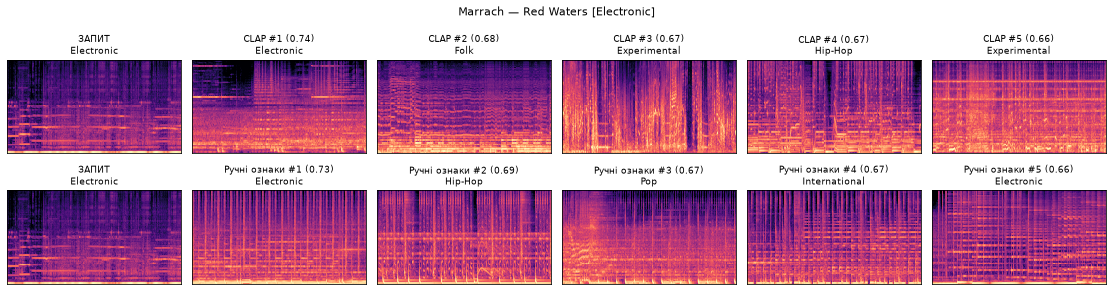

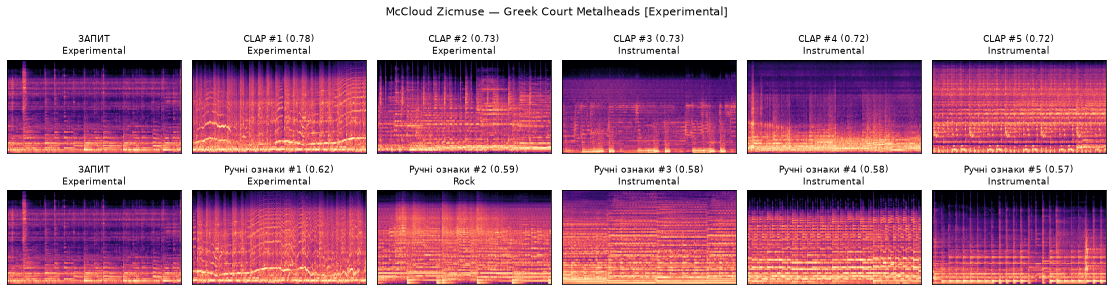

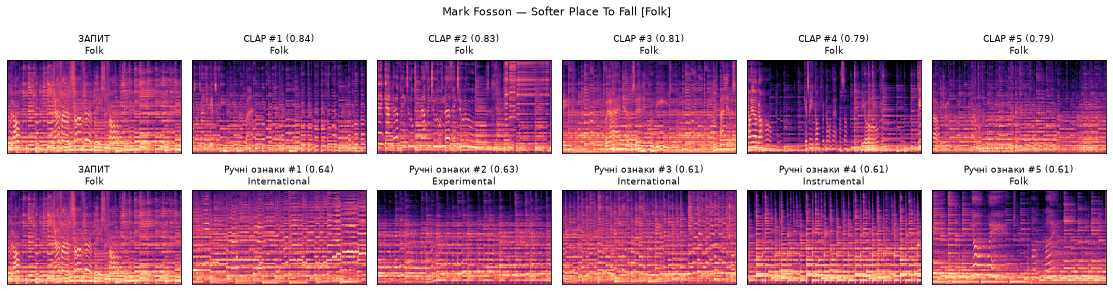

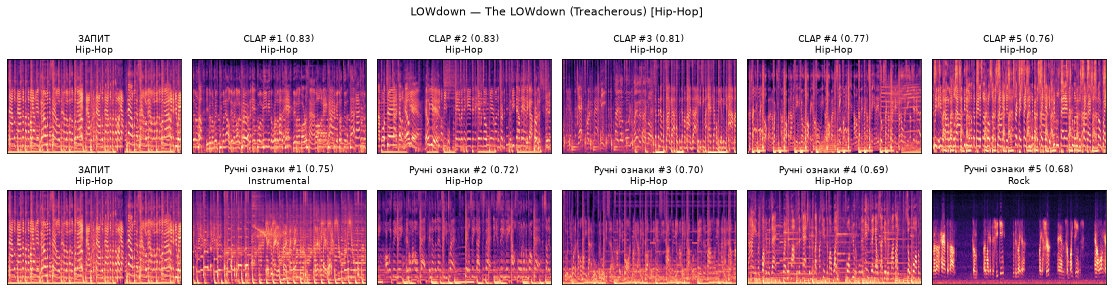

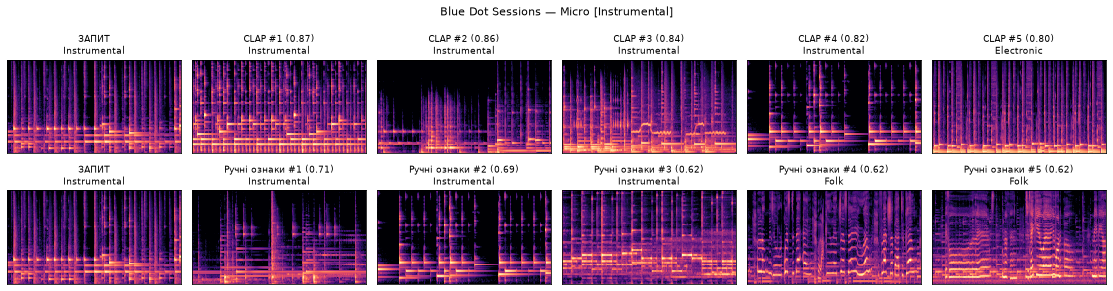

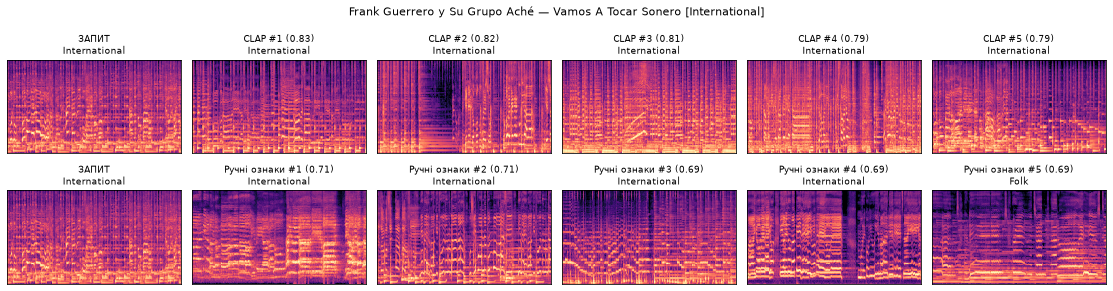

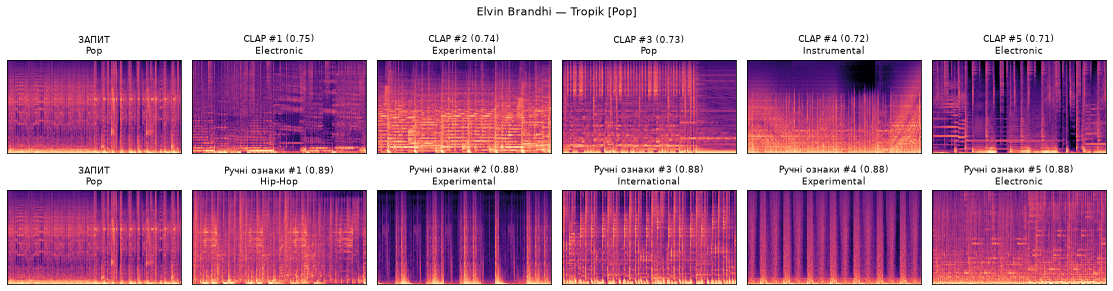

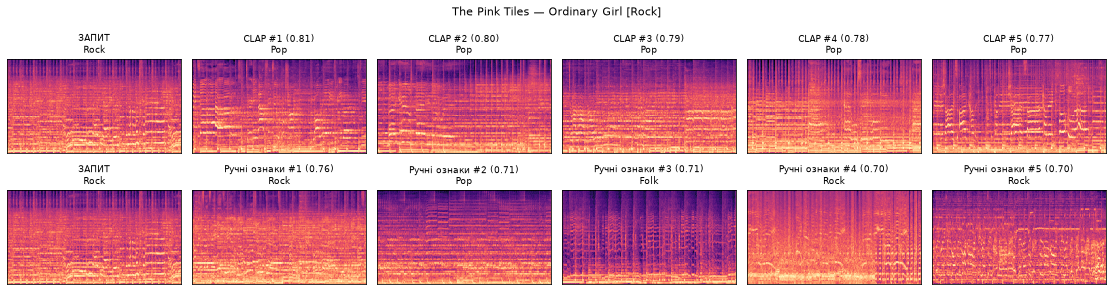

In [3]:
def mel(track_id, start):
    y, sr = librosa.load(track_path(track_id), sr=22050, offset=float(start), duration=CHUNK_S)
    return librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=96), ref=np.max), sr

for qid in queries:
    q = tracks.loc[qid]
    fig, axes = plt.subplots(2, 6, figsize=(16, 4.2), dpi=70)
    for row, (key, label) in enumerate(METHODS.items()):
        items = [(qid, 10.0, "ЗАПИТ")] + [(r.track_id, r.start_s, f"{label} #{i} ({r.score:.2f})")
                                          for i, r in enumerate(results[qid, key].itertuples(), 1)]
        for ax, (tid, start, name) in zip(axes[row], items):
            S, sr = mel(tid, start)
            librosa.display.specshow(S, sr=sr, ax=ax, cmap="magma")
            ax.set_title(f"{name}\n{tracks.loc[tid].genre}", fontsize=9)
    fig.suptitle(f"{q.artist} — {q.title} [{q.genre}]", fontsize=11)
    plt.tight_layout(); plt.show()

## 2D-проєкція векторів треків (UMAP)

Вектор треку — середнє векторів його шматків. Колір — жанр. Якщо жанри утворюють «острови», простір відображає звучання.

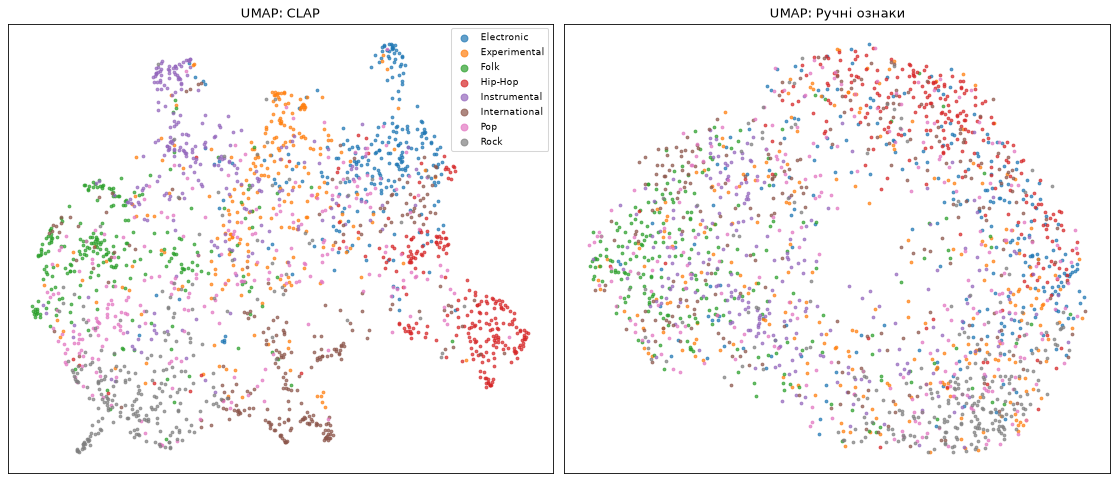

In [4]:
import umap
starts = np.flatnonzero(np.r_[True, chunks.track_id.values[1:] != chunks.track_id.values[:-1]])
counts = np.diff(np.r_[starts, len(chunks)])[:, None]
genres = tracks.loc[chunks.track_id.values[starts], "genre"].values
names = sorted(set(genres))
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=75)
for ax, (key, label) in zip(axes, METHODS.items()):
    tv = l2norm(np.add.reduceat(c[key], starts, axis=0) / counts)
    xy = umap.UMAP(n_neighbors=20, min_dist=0.2, metric="cosine", random_state=0).fit_transform(tv)
    for i, g in enumerate(names):
        m = genres == g
        ax.scatter(xy[m, 0], xy[m, 1], s=7, alpha=0.7, color=plt.cm.tab10(i), label=g)
    ax.set_title(f"UMAP: {label}"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=2.5, fontsize=9)
plt.tight_layout(); plt.show()

## Precision@5 за жанром — грубий індикатор

Запит — шматок 10–20 с **кожного** треку; рахуємо частку top-5 того самого жанру. Випадковий вибір дав би ≈0.125 (8 жанрів).
Увага: жанр ≠ «звучить схоже». Це лише перевірка, що пошук не випадковий.

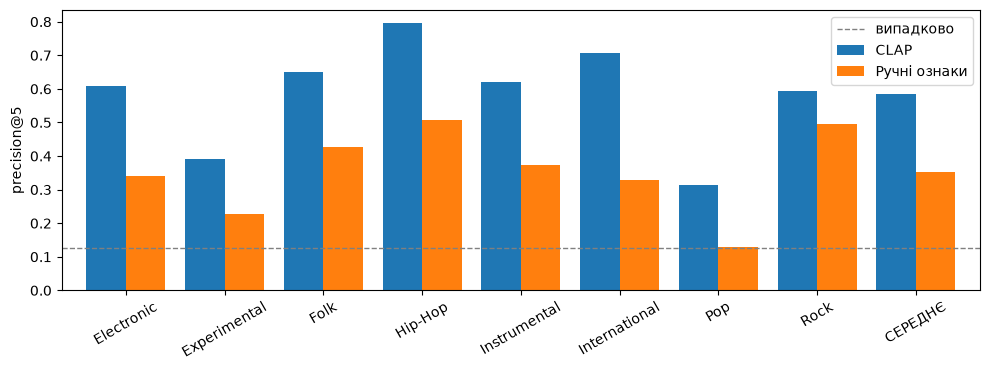

,CLAP,Ручні ознаки
Electronic,0.607,0.342
Experimental,0.390,0.229
Folk,0.650,0.426
Hip-Hop,0.795,0.507
Instrumental,0.620,0.374
International,0.708,0.327
Pop,0.313,0.129
Rock,0.593,0.494
СЕРЕДНЄ,0.584,0.353


In [5]:
p5 = pd.DataFrame({label: precision_at_k(c[key], chunks, tracks) for key, label in METHODS.items()})
p5.loc["СЕРЕДНЄ"] = p5.mean()
ax = p5.plot.bar(figsize=(10, 3.8), rot=30, width=0.8)
ax.axhline(0.125, color="gray", ls="--", lw=1, label="випадково"); ax.set_ylabel("precision@5"); ax.legend()
plt.tight_layout(); plt.show()
p5.round(3)

## Висновок

**Що пораховано** (підмножина fma_small: 1999 треків, по ~250 на жанр, 9995 шматків по 10 с; 1 битий mp3 пропущено):

| | CLAP | Ручні ознаки | випадково |
|---|---|---|---|
| precision@5 за жанром (усі 1999 треків як запити) | **0.584** | 0.353 | 0.125 |
| того ж жанру у top-5 для 8 запитів вище | 23 / 40 | 17 / 40 | 5 / 40 |

- CLAP кращий за ручні ознаки в кожному жанрі; найсильніше — Hip-Hop (0.80), International (0.71), Folk (0.65); найслабше — Pop (0.31) та Experimental (0.39), де й сам жанр звуково розмитий.
- На UMAP у CLAP жанри помітно групуються, у ручних ознак — слабше.
- Модель: `laion/larger_clap_music_and_speech`. Запланована `laion/larger_clap_music` у цій версії `transformers` виявилась неробочою (precision@5 ≈ 0.18–0.20, zero-shot на рівні випадкового), тому її замінено — деталі в коментарі в `scripts/build_embeddings.py`.
- Час: 2000 треків ≈ 16,5 хв на MacBook Air M1 (≈0,5 с/трек, майже весь час — CLAP). Повні 8000 треків ≈ 65–70 хв.

**Чого ці цифри НЕ доводять.** Збіг жанру — лише грубий індикатор того, що пошук не випадковий. Він не каже, чи знайдені треки *звучать схоже на хук*: два рок-треки можуть бути зовсім різними, а схожий за звучанням трек може мати інший жанр (див. запит Rock: 0/5 за жанром у CLAP — саме такий випадок треба перевірити на слух).

**Вердикт етапу 0 — ще НЕ винесено.** Він чекає на прослуховування автором: відкрий `listening/index.html`, послухай 8 запитів і познач «схоже / ні». Критерій готовності етапу 0: для більшості запитів ≥2–3 з 5 результатів CLAP справді звучать схоже. Якщо так — можна переходити до етапу 1 (бот); якщо ні — спершу розбиратися (інша модель, довжина шматків, поєднання з ручними ознаками).

Оцінки автора: _(буде дописано після прослуховування)_